# Used Car Price Prediction: End-to-End Machine Learning Pipeline

**Objective:** build an ML model that predicts the selling price of a used car from historical data.

**Process flow:** Data Cleaning -> Feature Engineering -> Outlier Handling -> Encoding -> Log Transformation -> Model Comparison -> Final Selection -> Save Model

## 1. Importing libraries

In [1]:
import pickle
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

## 2. Read data

In [2]:
df = pd.read_csv("../dataset/car_data.csv")
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 3. Data information and missing values

In [3]:
print("Data Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())

Data Information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


## 4. Data cleaning: remove duplicates

Duplicate rows can end up in both the train and the test set, which makes the test score look better than it really is. So they are removed first.

In [4]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicates}")

if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print(f"Shape after removing duplicates: {df.shape}")

Number of duplicate rows found: 763
Shape after removing duplicates: (3577, 8)


## 5. Feature engineering

1. Split `name` into brand and model (the first two words) and join them as `brand_model`, e.g. `Maruti Swift`.
2. Replace `year` with `car_age` (price depends on how old the car is).
3. Group rare cars (fewer than 15 rows) into `Other` to avoid overfitting.

In [5]:
# 1. extract brand and model from the name
# example: 'Maruti Swift Dzire VDI' -> brand = 'Maruti', model = 'Swift'
df['brand'] = df['name'].apply(lambda x: x.split(' ')[0])
df['model'] = df['name'].apply(lambda x: x.split(' ')[1] if len(x.split(' ')) > 1 else x.split(' ')[0])
df['brand_model'] = df['brand'] + ' ' + df['model']

# 2. drop columns that are no longer needed
df.drop(['name', 'brand', 'model'], axis=1, inplace=True)

# 3. car age
current_year = 2026
df['car_age'] = current_year - df['year']
df.drop('year', axis=1, inplace=True)

# 4. group rare cars: cars with fewer than 15 rows become 'Other'
counts = df['brand_model'].value_counts()
top_cars = counts[counts >= 15].index
df['brand_model'] = df['brand_model'].apply(lambda x: x if x in top_cars else 'Other')

print("New features created: 'brand_model' and 'car_age'")
df.head()

New features created: 'brand_model' and 'car_age'


,selling_price,km_driven,fuel,seller_type,transmission,owner,brand_model,car_age
0,60000,70000,Petrol,Individual,Manual,First Owner,Maruti 800,19
1,135000,50000,Petrol,Individual,Manual,First Owner,Maruti Wagon,19
2,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai Verna,14
3,250000,46000,Petrol,Individual,Manual,First Owner,Other,9
4,450000,141000,Diesel,Individual,Manual,Second Owner,Honda Amaze,12


## 6. Outlier handling

Prices are clipped to the 1st-99th percentile and cars with 300,000 km or more are removed, so a few extreme rows do not distort the model.

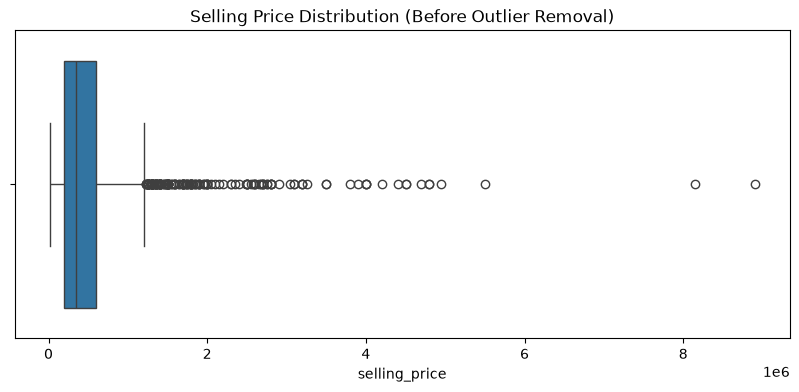

Rows dropped due to outliers: 82


In [6]:
# boxplot before removing outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['selling_price'])
plt.title("Selling Price Distribution (Before Outlier Removal)")
plt.show()

q_low = df['selling_price'].quantile(0.01)
q_high = df['selling_price'].quantile(0.99)

df_clean = df[(df['selling_price'] >= q_low) & (df['selling_price'] <= q_high)]
df_clean = df_clean[df_clean['km_driven'] < 300000]

print(f"Rows dropped due to outliers: {df.shape[0] - df_clean.shape[0]}")

## 7. Categorical encoding

- `owner` has a natural order, so it gets an ordinal number.
- `brand_model`, `fuel`, `seller_type` and `transmission` have no order, so they are one-hot encoded.

In [7]:
# ordinal encoding for owner
owner_map = {
    'First Owner': 1,
    'Second Owner': 2,
    'Third Owner': 3,
    'Fourth & Above Owner': 4,
    'Test Drive Car': 0
}
df_clean = df_clean.copy()
df_clean['owner'] = df_clean['owner'].map(owner_map)

# one-hot encoding
df_encoded = pd.get_dummies(df_clean, columns=['brand_model', 'fuel', 'seller_type', 'transmission'], drop_first=True)

print("Encoding complete. New data shape:", df_encoded.shape)

Encoding complete. New data shape: (3495, 70)


## 8. Log transformation of the target and train-test split

Prices are right-skewed, so we train on `log1p(price)` and convert predictions back with `expm1`.

In [8]:
X = df_encoded.drop('selling_price', axis=1)
y_raw = df_encoded['selling_price']

# log transformation
y = np.log1p(y_raw)

# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data split into train and test sets.")

Data split into train and test sets.


## 9. Model training and comparison

Three models are trained on the same data and scored on the same test set:

1. **Linear Regression** - simple baseline
2. **Random Forest** - many independent deep trees, averaged
3. **XGBoost** - many shallow trees built one after another, each fixing the previous errors

In [9]:
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred_log = model.predict(X_test)

    # reverse the log transformation to get real prices in rupees
    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    r2 = r2_score(y_test_real, y_pred_real)
    mae = mean_absolute_error(y_test_real, y_pred_real)
    results[name] = r2 * 100

    print(f"{name}: R2 = {r2*100:.2f}%  |  MAE = Rs {mae:,.0f}")

Linear Regression (Baseline): R2 = 60.56%  |  MAE = Rs 110,587
Random Forest: R2 = 69.83%  |  MAE = Rs 106,007
XGBoost: R2 = 72.41%  |  MAE = Rs 98,012


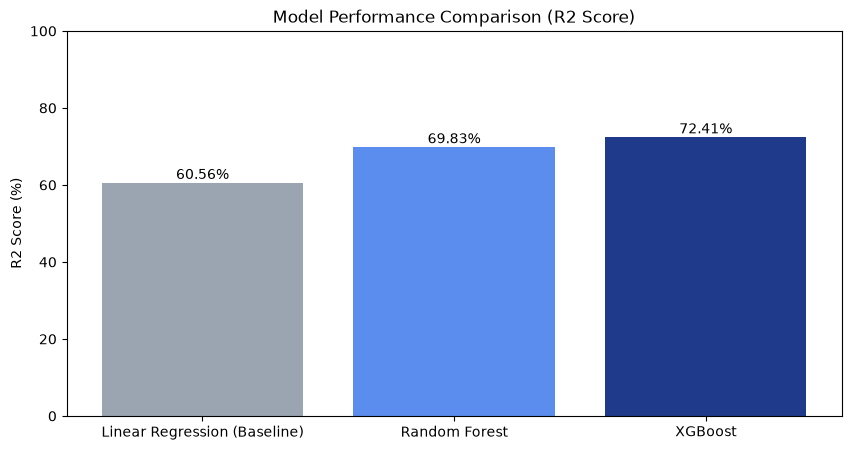

In [10]:
# bar chart for model comparison
plt.figure(figsize=(10, 5))
plt.bar(list(results.keys()), list(results.values()), color=['#9aa5b1', '#5b8def', '#1f3a8a'])
plt.title("Model Performance Comparison (R2 Score)")
plt.ylabel("R2 Score (%)")
plt.ylim(0, 100)
for index, value in enumerate(results.values()):
    plt.text(index, value + 1, f"{value:.2f}%", ha='center')
plt.show()

## 10. Save the best model

The pickle file stores everything `app.py` needs: the trained model, the exact column order, the list of popular cars and the brand-to-models map for the dropdowns.

In [11]:
os.makedirs('../models', exist_ok=True)

# brand -> list of models, used by the dropdowns in the app
# NOTE: names are kept exactly as they are in the data (no .capitalize()),
# so 'i20' and 'XUV500' still match the names in top_cars.
brand_model_dict = {}
for car in top_cars:
    brand_name, model_name = car.split(' ', 1)
    brand_model_dict.setdefault(brand_name, []).append(model_name)

for brand_name in brand_model_dict:
    brand_model_dict[brand_name] = sorted(brand_model_dict[brand_name])

# sanity check: every dropdown name must match a name in top_cars (this list should be empty)
mismatch = [f"{b} {m}" for b, ms in brand_model_dict.items() for m in ms if f"{b} {m}" not in top_cars]
print("Names not matching top_cars:", mismatch)

best_model = models["XGBoost"]

model_data = {
    'model': best_model,
    'columns': X_train.columns.tolist(),
    'top_cars': top_cars.tolist(),
    'brand_model_map': brand_model_dict
}

with open('../models/car_price_model.pkl', 'wb') as file:
    pickle.dump(model_data, file)

print("Model and brand-model map saved successfully.")

Names not matching top_cars: []
Model and brand-model map saved successfully.
